In [ ]:
# -*- coding: utf-8 -*-
# ============================================================
# 텍스트마이닝 (GPT-2 AI 리뷰 vs 사람 리뷰) — 코랩용
# 질문: 바이럴 마케팅에 쓰이는 AI 리뷰는 사람 리뷰와 어휘·주제·감성·표현 구조에서 어떻게 다른가?
# 입력: EDA_v2_결과.zip 하나만 업로드 (안의 eda_features.csv = 정제된 리뷰 40,214건)
# 분석
#   ② 어휘   : 단어 빈도 산점도(T1), 특징적인 2·3단어 표현과 상투구 비율(T2)
#   ③ 주제   : LDA 토픽 모델링 — 토픽 수 선택(T3), 토픽별 비중 차이(T4), 주제 다양성(T5)
#   ④ 감성   : 문장 위치별 감성 흐름(T6), NRC 8감정(T7)
#   ⑤ 관계   : 단어 동시출현 네트워크(T8), 중심 단어 비교(T9)
# 출력: 텍스트마이닝_결과.zip (그림 T1~T9, 표, 요약)
# 약 10~15분 소요 (토픽 모델링이 가장 오래 걸림)
# ============================================================

# %% 0. 환경 준비와 파일 업로드 ----------------------------------------
import sys, os, re, glob, json, math, zipfile, subprocess, warnings, functools, traceback
from pathlib import Path
from collections import Counter
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'vaderSentiment', 'nrclex'], check=False)
    subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null 2>&1', shell=True, check=False)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import networkx as nx
from scipy.stats import mannwhitneyu
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
warnings.filterwarnings('ignore')
try:
    display
except NameError:
    display = print
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)

KFONT = None
for f in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    if os.path.exists(f):
        font_manager.fontManager.addfont(f); plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=f).get_name()
if KFONT is None:
    for p in sorted(glob.glob('/usr/share/fonts/**/*', recursive=True) + glob.glob('C:/Windows/Fonts/*') + glob.glob('/Library/Fonts/*')):
        if re.search(r'(Nanum|NotoSansCJK|NotoSansKR|malgun|AppleSDGothic)', os.path.basename(p), re.I):
            try:
                font_manager.fontManager.addfont(p); plt.rcParams['font.family'] = KFONT = font_manager.FontProperties(fname=p).get_name(); break
            except Exception:
                continue
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 10.5, 'savefig.dpi': 300, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E6ECF2', 'axes.axisbelow': True,
                     'text.color': '#3E4C5E', 'axes.labelcolor': '#3E4C5E', 'xtick.color': '#3E4C5E', 'ytick.color': '#3E4C5E',
                     'axes.edgecolor': '#9AA6B2', 'axes.titlecolor': '#3E4C5E', 'legend.labelcolor': '#3E4C5E'})
# 색상 (EDA와 같은 파스텔 팔레트)
AI, HU = 'AI(GPT-2)', '사람'
GROUPS = [AI, HU]
COLORS = {AI: '#F2ABAE', HU: '#8DBDEB'}
EDGE = {AI: '#D9798A', HU: '#4F86B8'}
PERI, PERI_E = '#8F9FE0', '#5E6FBF'
MINT, MINT_E = '#A8D8C8', '#5FA894'
NEUTRAL, NEUTRAL_E, INK, INK2 = '#D5DCE4', '#9AA6B2', '#3E4C5E', '#7A8797'
CMAP_DIV = LinearSegmentedColormap.from_list('blue_white_pink', ['#4F86B8', '#C9D6E8', '#F4F6F8', '#F0C4C8', '#D9798A'])  # 사람 쪽 ← → AI 쪽
COMMUNITY = ['#8DBDEB', '#F2ABAE', '#A8D8C8', '#8F9FE0', '#F6C9A8', '#C9B6E4', '#BFD9E8']   # 네트워크 군집 색
SEED = 42
OUT = Path('textmining_results'); OUT.mkdir(exist_ok=True)
FAILED = []

def step(fn):
    """분석 하나가 실패해도 나머지는 계속 진행"""
    @functools.wraps(fn)
    def wrap(*a, **k):
        print(f'\n===== {fn.__doc__.strip().splitlines()[0] if fn.__doc__ else fn.__name__} =====')
        try:
            return fn(*a, **k)
        except Exception as e:
            FAILED.append(fn.__name__); print(f'  ✗ 실패: {type(e).__name__}: {e}'); traceback.print_exc(limit=2)
    return wrap

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

def rb(a, b):
    """순위 이연 상관 r (+ = AI 쪽이 큼)"""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    return 2 * mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1 if len(a) and len(b) else np.nan

def place_labels(ax, xs, ys, names, fontsize=8.5, color=INK):
    """이름표가 서로 겹치지 않게 빈 자리를 찾아 붙임"""
    ax.figure.canvas.draw(); placed = []
    for x, y, nm in zip(xs, ys, names):
        px, py = ax.transData.transform((x, y)); w = 6.5 * len(nm) + 6
        for dx, dy, ha in [(5, 4, 'left'), (5, -12, 'left'), (-5, 4, 'right'), (-5, -12, 'right'), (5, 14, 'left'), (5, -22, 'left'), (-5, 14, 'right'), (-5, -22, 'right')]:
            x0 = px + dx if ha == 'left' else px + dx - w
            box = (x0, py + dy, x0 + w, py + dy + 11)
            if all(box[2] < b[0] or box[0] > b[2] or box[3] < b[1] or box[1] > b[3] for b in placed): break
        placed.append(box)
        ax.annotate(nm, (x, y), textcoords='offset points', xytext=(dx * 0.75, dy * 0.75), ha=ha, fontsize=fontsize, color=color)

DATA_DIR = Path('/content' if IN_COLAB else '.')
if IN_COLAB:
    from google.colab import files
    files.upload()   # EDA_v2_결과.zip 선택 (또는 eda_features.csv)
for z in DATA_DIR.glob('*.zip'):
    with zipfile.ZipFile(z) as zf:
        for n in zf.namelist():
            if n.endswith(('eda_features.csv', '10_통념점검.csv')):
                (DATA_DIR / Path(n).name).write_bytes(zf.read(n))
hits = sorted(DATA_DIR.glob('**/eda_features.csv'))
assert hits, 'eda_features.csv가 없어요. EDA_v2_결과.zip을 업로드하세요.'
df = pd.read_csv(hits[0])
df['text_clean'] = df['text_clean'].fillna('').astype(str)
is_ai = (df['group'] == AI).values
N = {g: int((df['group'] == g).sum()) for g in GROUPS}
print(f'리뷰 {len(df):,}건 ({AI} {N[AI]:,} / {HU} {N[HU]:,})')

# 불용어: 어휘·문체 분석(T1·T2)에서는 남기고(기능어도 문체 단서), 주제·네트워크(T3~T9)에서는 뺌(내용어만 의미 있음)
EXTRA_STOP = {'just', 'really', 'got', 'get', 'would', 'also', 'one', 'use', 'used', 'using', 'like', 'make', 'made', 'thing', 'things',
              'bit', 'lot', 've', 'don', 'didn', 'doesn', 'isn', 'll', 'im', 'm', 's', 't', 'd', 'went', 'go', 'going', 'say', 'said'}
CONTENT_STOP = set(ENGLISH_STOP_WORDS) | EXTRA_STOP

Saving EDA_v2_결과.zip to EDA_v2_결과.zip
리뷰 40,214건 (AI(GPT-2) 20,052 / 사람 20,162)



===== T1 단어 빈도 산점도 =====


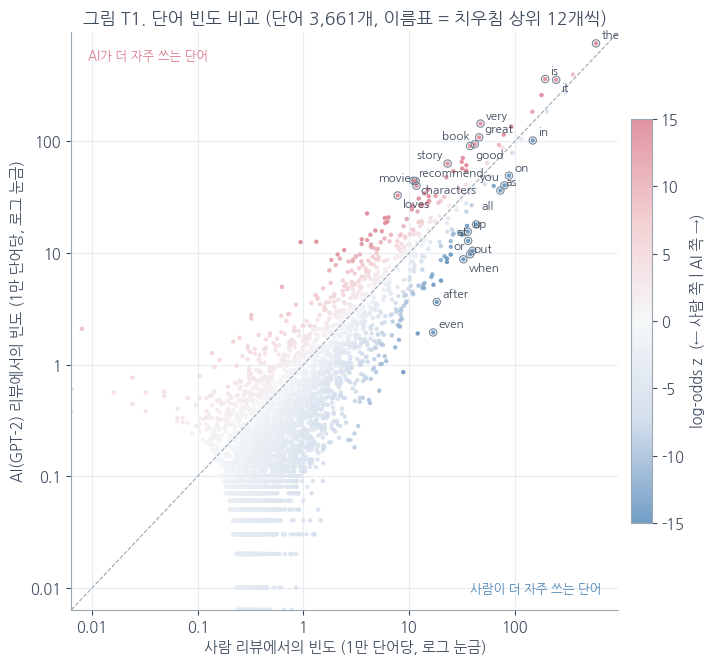

  AI 쪽 상위 12: is, very, great, the, good, it, book, recommend, characters, story, movie, loves
  사람 쪽 상위 12: at, or, when, you, as, on, even, out, all, after, in, up
  치우침 상위 30개 중 불용어 비율: AI 쪽 37%, 사람 쪽 100%


In [ ]:
# %% 1. 어휘: 단어 빈도 산점도 (T1) --------------------------------------
# 점 하나 = 단어 하나. 대각선 위 = AI가 더 자주, 아래 = 사람이 더 자주. 색 = log-odds z(얼마나 확실하게 한쪽에 치우쳤나)
def logodds(Xa, Xh):
    ya, yh = np.asarray(Xa.sum(0)).ravel().astype(float), np.asarray(Xh.sum(0)).ravel().astype(float)
    alpha = ya + yh; a0 = alpha.sum(); na, nh = ya.sum(), yh.sum()
    delta = np.log((ya + alpha) / (na + a0 - ya - alpha)) - np.log((yh + alpha) / (nh + a0 - yh - alpha))
    return delta / np.sqrt(1 / (ya + alpha) + 1 / (yh + alpha)), ya, yh

@step
def word_scatter():
    """T1 단어 빈도 산점도"""
    cv = CountVectorizer(token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b", min_df=30)
    X = cv.fit_transform(df['text_clean']); vocab = np.array(cv.get_feature_names_out())
    z, ya, yh = logodds(X[is_ai], X[~is_ai])
    fa, fh = ya / ya.sum() * 1e4, yh / yh.sum() * 1e4          # 1만 단어당 빈도
    lex = pd.DataFrame({'단어': vocab, f'{AI} (1만 단어당)': fa, f'{HU} (1만 단어당)': fh, 'log-odds z': z,
                        '불용어': [w in ENGLISH_STOP_WORDS for w in vocab]}).sort_values('log-odds z', ascending=False)
    lex.round(3).to_csv(OUT / 'T1_단어빈도_logodds.csv', index=False, encoding='utf-8-sig')
    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    lo = np.log10(np.r_[fa, fh][np.r_[fa, fh] > 0].min()) - 0.1
    xa, xh = np.log10(np.maximum(fa, 10 ** lo)), np.log10(np.maximum(fh, 10 ** lo))
    zc = np.clip(z, -15, 15)
    sc = ax.scatter(xh, xa, c=zc, cmap=CMAP_DIV, vmin=-15, vmax=15, s=10, alpha=0.8, linewidths=0, rasterized=True)
    hi = max(xa.max(), xh.max()) + 0.1; ax.plot([lo, hi], [lo, hi], color=NEUTRAL_E, lw=0.8, ls='--')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    top = pd.concat([lex.head(12), lex.tail(12)])
    idx = [np.where(vocab == w)[0][0] for w in top['단어']]
    ax.scatter(xh[idx], xa[idx], s=28, facecolors='none', edgecolors=INK2, linewidths=0.8)
    place_labels(ax, xh[idx], xa[idx], list(top['단어']))
    ticks = np.arange(math.ceil(lo), math.floor(hi) + 1)
    ax.set_xticks(ticks, [f'{10.0 ** t:g}' for t in ticks]); ax.set_yticks(ticks, [f'{10.0 ** t:g}' for t in ticks])
    ax.set_xlabel(f'{HU} 리뷰에서의 빈도 (1만 단어당, 로그 눈금)'); ax.set_ylabel(f'{AI} 리뷰에서의 빈도 (1만 단어당, 로그 눈금)')
    cb = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.02); cb.set_label('log-odds z  (← 사람 쪽 | AI 쪽 →)')
    ax.text(0.03, 0.97, 'AI가 더 자주 쓰는 단어', transform=ax.transAxes, va='top', fontsize=9, color=EDGE[AI])
    ax.text(0.97, 0.03, '사람이 더 자주 쓰는 단어', transform=ax.transAxes, ha='right', fontsize=9, color=EDGE[HU])
    ax.set_title(f'그림 T1. 단어 빈도 비교 (단어 {len(vocab):,}개, 이름표 = 치우침 상위 12개씩)')
    save(fig, 'figT1_단어빈도_산점도.png')
    sw_ai = lex.head(30)['불용어'].mean(); sw_hu = lex.tail(30)['불용어'].mean()
    print(f'  AI 쪽 상위 12: {", ".join(lex.head(12)["단어"])}')
    print(f'  사람 쪽 상위 12: {", ".join(lex.tail(12)["단어"][::-1])}')
    print(f'  치우침 상위 30개 중 불용어 비율: AI 쪽 {sw_ai:.0%}, 사람 쪽 {sw_hu:.0%}')
    return lex
LEX = word_scatter()


===== T2 특징적인 2·3단어 표현과 상투구 비율 =====
  흔한 3단어 연쇄 2,842개 기준 상투구 비율 중앙값: AI(GPT-2) 0.283 vs 사람 0.061 (r = +0.70)


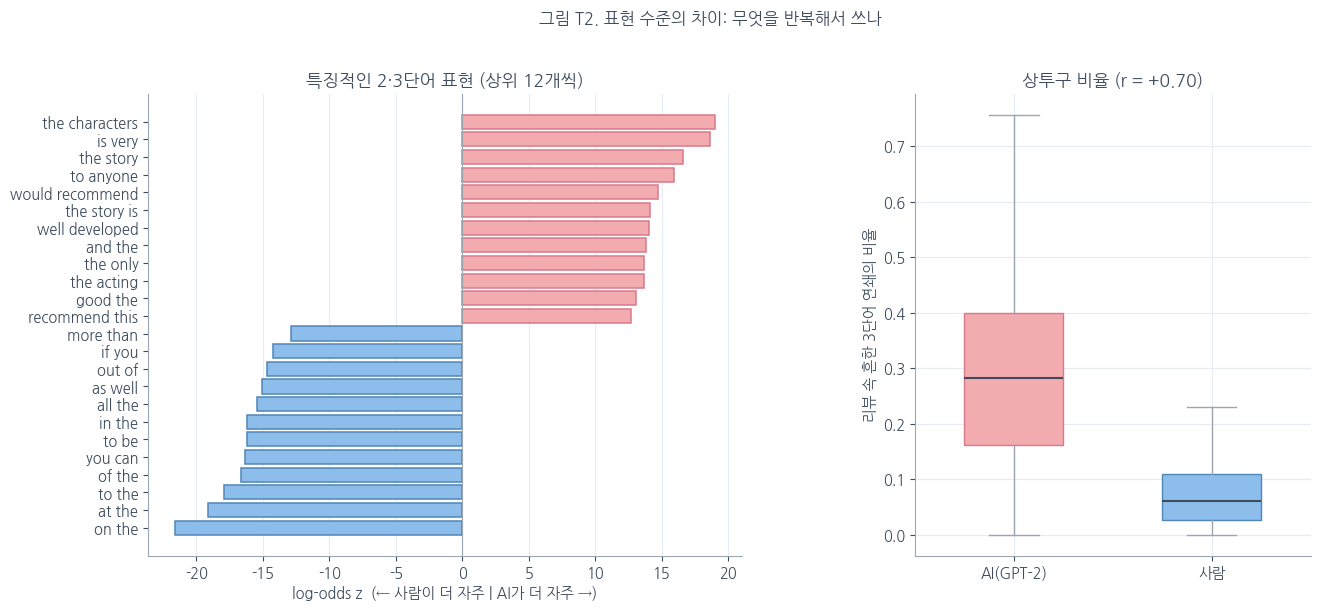

In [ ]:
# %% 2. 어휘: 특징적인 2·3단어 표현과 상투구 비율 (T2) ---------------------
@step
def ngram_cliche():
    """T2 특징적인 2·3단어 표현과 상투구 비율"""
    cv = CountVectorizer(ngram_range=(2, 3), token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b", min_df=20)
    X = cv.fit_transform(df['text_clean']); vocab = np.array(cv.get_feature_names_out())
    z, ya, yh = logodds(X[is_ai], X[~is_ai])
    ng = pd.DataFrame({'표현': vocab, 'z': z, f'{AI} 빈도': ya.astype(int), f'{HU} 빈도': yh.astype(int)}).sort_values('z')
    ng.to_csv(OUT / 'T2_2-3단어_logodds.csv', index=False, encoding='utf-8-sig')
    # 상투구 비율: 리뷰 속 3단어 연쇄 중 "50개 이상의 서로 다른 리뷰에 나오는 흔한 연쇄"의 비율 (클수록 남들이 다 쓰는 말)
    cv3 = CountVectorizer(ngram_range=(3, 3), token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b", min_df=1)
    X3 = cv3.fit_transform(df['text_clean'])
    docfreq = np.asarray((X3 > 0).sum(0)).ravel(); common = docfreq >= 50
    tot = np.asarray(X3.sum(1)).ravel(); com = np.asarray(X3[:, common].sum(1)).ravel()
    df['cliche_ratio'] = np.where(tot > 0, com / np.maximum(tot, 1), np.nan)
    r = rb(df.loc[is_ai, 'cliche_ratio'], df.loc[~is_ai, 'cliche_ratio'])
    med = df.groupby('group')['cliche_ratio'].median().reindex(GROUPS)
    print(f'  흔한 3단어 연쇄 {common.sum():,}개 기준 상투구 비율 중앙값: {AI} {med[AI]:.3f} vs {HU} {med[HU]:.3f} (r = {r:+.2f})')
    fig, axs = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.5, 1], 'wspace': 0.35})
    top = pd.concat([ng.head(12), ng.tail(12)])
    axs[0].barh(top['표현'], top['z'], color=[COLORS[AI] if v > 0 else COLORS[HU] for v in top['z']],
                edgecolor=[EDGE[AI] if v > 0 else EDGE[HU] for v in top['z']], linewidth=1.1)
    axs[0].axvline(0, color=NEUTRAL_E, lw=0.8); axs[0].grid(axis='y', visible=False)
    axs[0].set_xlabel('log-odds z  (← 사람이 더 자주 | AI가 더 자주 →)'); axs[0].set_title('특징적인 2·3단어 표현 (상위 12개씩)')
    data = [df.loc[df['group'] == g, 'cliche_ratio'].dropna() for g in GROUPS]
    bp = axs[1].boxplot(data, patch_artist=True, showfliers=False, widths=0.5, medianprops=dict(color=INK, lw=1.5),
                        whiskerprops=dict(color=NEUTRAL_E), capprops=dict(color=NEUTRAL_E))
    for p, g in zip(bp['boxes'], GROUPS): p.set_facecolor(COLORS[g]); p.set_edgecolor(EDGE[g])
    axs[1].set_xticks([1, 2], GROUPS); axs[1].set_ylabel('리뷰 속 흔한 3단어 연쇄의 비율')
    axs[1].set_title(f'상투구 비율 (r = {r:+.2f})')
    fig.suptitle('그림 T2. 표현 수준의 차이: 무엇을 반복해서 쓰나', y=1.02, fontsize=12)
    save(fig, 'figT2_표현_상투구.png')
    return {'상투구 중앙값 AI': med[AI], '상투구 중앙값 사람': med[HU], 'r': r}
CLICHE = ngram_cliche()

토픽 모델링 어휘 4,406개

===== T3 토픽 수 선택 =====
  K= 6  일관성 -2.083  perplexity 1028
  K= 8  일관성 -2.085  perplexity 1054
  K=10  일관성 -2.115  perplexity 1073
  K=12  일관성 -2.326  perplexity 1050


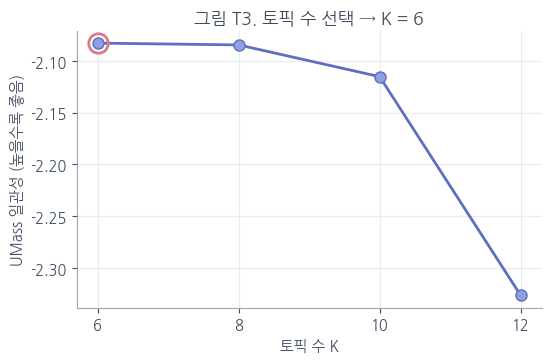


===== T4 토픽별 AI·사람 비중 차이 =====


,토픽,상위 단어,AI(GPT-2) 평균 비중,사람 평균 비중,"차이(AI-사람, %p)",95% CI(±%p),AI(GPT-2) 대표 토픽 비율,사람 대표 토픽 비율
0,토픽 4,"great, light, works, easy, product, good",0.172,0.105,6.707,0.447,0.178,0.083
1,토픽 1,"size, fit, great, comfortable, love, little",0.189,0.128,6.087,0.513,0.196,0.126
2,토픽 3,"loves, great, dog, bought, love, son",0.180,0.123,5.689,0.497,0.186,0.117
3,토픽 2,"book, story, read, good, characters, movie",0.281,0.234,4.700,0.708,0.301,0.271
4,토픽 5,"easy, water, little, box, good, plastic",0.099,0.178,-7.910,0.426,0.082,0.186
5,토픽 6,"time, work, does, new, better, did",0.080,0.232,-15.274,0.401,0.057,0.216


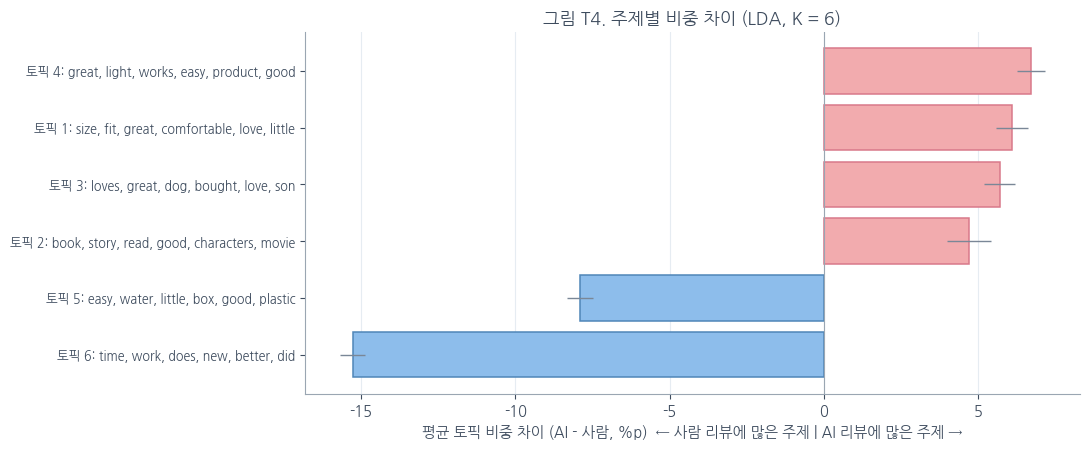


===== T5 주제 다양성 (리뷰 한 건이 여러 주제를 다루는 정도) =====


,AI(GPT-2),사람,r
짧음(1분위),0.474,0.531,-0.129
2분위,0.382,0.494,-0.243
3분위,0.341,0.485,-0.412
긺(4분위),0.302,0.512,-0.493


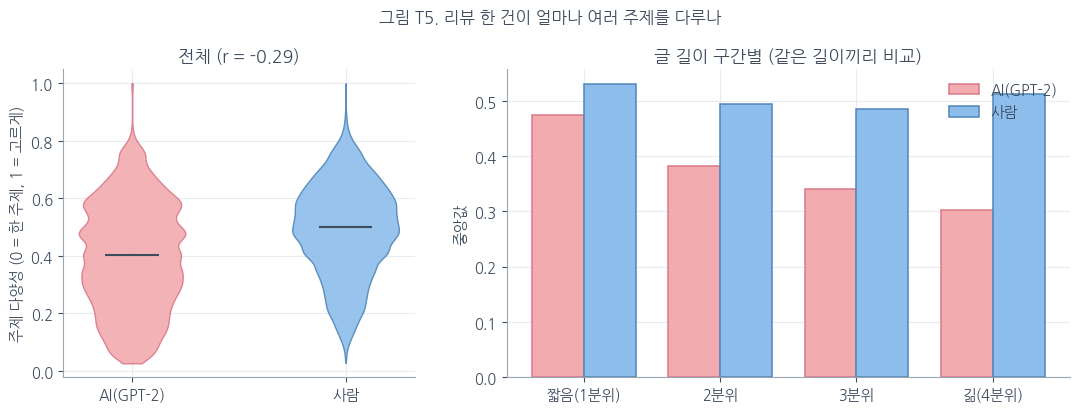

In [ ]:
# %% 3. 주제: LDA 토픽 모델링 (T3·T4·T5) --------------------------------
# 리뷰마다 "여러 주제가 섞여 있다"고 보고, 각 주제의 비율을 추정. 불용어는 빼고 내용어만 씀
K_CANDIDATES = [6, 8, 10, 12]   # 시험해 볼 토픽 수
K_FIXED = None                  # 숫자를 넣으면(예: 8) 자동 선택 대신 그 값으로 고정
TOPIC_NAMES = {}                # 결과를 보고 이름을 붙이고 싶으면 {0: '배송·포장', 1: '책 줄거리', ...} 처럼 채운 뒤 이 셀만 다시 실행

cv_t = CountVectorizer(stop_words=list(CONTENT_STOP), token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", min_df=20, max_df=0.4)
Xt = cv_t.fit_transform(df['text_clean']); vocab_t = np.array(cv_t.get_feature_names_out())
Xb = (Xt > 0).astype(np.int32).tocsc(); dfreq = np.asarray(Xb.sum(0)).ravel()
print(f'토픽 모델링 어휘 {len(vocab_t):,}개')

def umass(top_idx):
    """UMass 일관성: 한 토픽의 상위 단어들이 실제로 같은 리뷰에 함께 나오는 정도 (0에 가까울수록 좋음)"""
    s, n = 0.0, 0
    for i in range(1, len(top_idx)):
        for j in range(i):
            co = Xb[:, top_idx[i]].multiply(Xb[:, top_idx[j]]).sum()
            s += math.log((co + 1) / dfreq[top_idx[j]]); n += 1
    return s / n

@step
def choose_k():
    """T3 토픽 수 선택"""
    rows, models = [], {}
    for k in ([K_FIXED] if K_FIXED else K_CANDIDATES):
        lda = LatentDirichletAllocation(n_components=k, learning_method='online', batch_size=2048, max_iter=10,
                                        random_state=SEED, n_jobs=-1).fit(Xt)
        coh = np.mean([umass(np.argsort(-t)[:10]) for t in lda.components_])
        rows.append({'토픽 수': k, 'UMass 일관성': coh, 'perplexity': lda.perplexity(Xt)}); models[k] = lda
        print(f'  K={k:2d}  일관성 {coh:.3f}  perplexity {rows[-1]["perplexity"]:.0f}')
    sel = pd.DataFrame(rows); best = int(sel.loc[sel['UMass 일관성'].idxmax(), '토픽 수'])
    sel.round(3).to_csv(OUT / 'T3_토픽수_선택.csv', index=False, encoding='utf-8-sig')
    if len(sel) > 1:
        fig, ax = plt.subplots(figsize=(6, 3.6))
        ax.plot(sel['토픽 수'], sel['UMass 일관성'], 'o-', color=PERI_E, mfc=PERI, ms=8, lw=2)
        ax.plot(best, sel.set_index('토픽 수').loc[best, 'UMass 일관성'], 'o', ms=14, mfc='none', mec=EDGE[AI], mew=2)
        ax.set_xticks(sel['토픽 수']); ax.set_xlabel('토픽 수 K'); ax.set_ylabel('UMass 일관성 (높을수록 좋음)')
        ax.set_title(f'그림 T3. 토픽 수 선택 → K = {best}')
        save(fig, 'figT3_토픽수선택.png')
    return models[best], best
_res = choose_k()
LDA, K = _res if _res else (None, 0)

@step
def topic_compare():
    """T4 토픽별 AI·사람 비중 차이"""
    theta = LDA.transform(Xt); theta = theta / theta.sum(1, keepdims=True)
    words = [', '.join(vocab_t[np.argsort(-t)[:6]]) for t in LDA.components_]
    names = [TOPIC_NAMES.get(i, f'토픽 {i + 1}') for i in range(K)]
    ma, mh = theta[is_ai].mean(0), theta[~is_ai].mean(0)
    se = np.sqrt(theta[is_ai].var(0) / is_ai.sum() + theta[~is_ai].var(0) / (~is_ai).sum())
    dom = theta.argmax(1)
    tt = pd.DataFrame({'토픽': names, '상위 단어': words, f'{AI} 평균 비중': ma, f'{HU} 평균 비중': mh, '차이(AI-사람, %p)': 100 * (ma - mh),
                       '95% CI(±%p)': 100 * 1.96 * se,
                       f'{AI} 대표 토픽 비율': [(dom[is_ai] == i).mean() for i in range(K)], f'{HU} 대표 토픽 비율': [(dom[~is_ai] == i).mean() for i in range(K)]})
    tt = tt.sort_values('차이(AI-사람, %p)', ascending=False).reset_index(drop=True)
    tt.round(4).to_csv(OUT / 'T4_토픽_비교.csv', index=False, encoding='utf-8-sig'); display(tt.round(3))
    d = tt.iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.55 * K + 1.4))
    ax.barh(range(K), d['차이(AI-사람, %p)'], xerr=d['95% CI(±%p)'], color=[COLORS[AI] if v > 0 else COLORS[HU] for v in d['차이(AI-사람, %p)']],
            edgecolor=[EDGE[AI] if v > 0 else EDGE[HU] for v in d['차이(AI-사람, %p)']], linewidth=1.1, error_kw=dict(ecolor=INK2, lw=1))
    ax.set_yticks(range(K), [f"{n}: {w}" for n, w in zip(d['토픽'], d['상위 단어'])], fontsize=9)
    ax.axvline(0, color=NEUTRAL_E, lw=0.8); ax.grid(axis='y', visible=False)
    ax.set_xlabel('평균 토픽 비중 차이 (AI − 사람, %p)  ← 사람 리뷰에 많은 주제 | AI 리뷰에 많은 주제 →'.replace('−', '-'))
    ax.set_title(f'그림 T4. 주제별 비중 차이 (LDA, K = {K})')
    save(fig, 'figT4_토픽비중차이.png')
    df[[f'topic_{i + 1}' for i in range(K)]] = theta
    return tt, theta
TOPICS = topic_compare()

@step
def topic_diversity():
    """T5 주제 다양성 (리뷰 한 건이 여러 주제를 다루는 정도)"""
    theta = TOPICS[1]
    ent = -(theta * np.log(np.clip(theta, 1e-12, 1))).sum(1) / np.log(K)   # 0 = 한 주제만, 1 = 모든 주제 고르게
    df['topic_entropy'] = ent
    r = rb(ent[is_ai], ent[~is_ai]); med = pd.Series({g: np.median(ent[(df['group'] == g).values]) for g in GROUPS})
    # 길이 영향 통제: 단어 수 구간별로도 비교 (짧은 글은 주제가 적을 수밖에 없음)
    bins = pd.qcut(df['n_words'], 4, labels=['짧음(1분위)', '2분위', '3분위', '긺(4분위)'])
    by_len = pd.DataFrame({g: pd.Series(ent[(df['group'] == g).values]).groupby(bins[(df['group'] == g).values].values).median() for g in GROUPS})
    by_len['r'] = [rb(ent[is_ai & (bins == b).values], ent[~is_ai & (bins == b).values]) for b in by_len.index]
    display(by_len.round(3)); by_len.round(4).to_csv(OUT / 'T5_주제다양성_길이별.csv', encoding='utf-8-sig')
    fig, axs = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1, 1.6]})
    vp = axs[0].violinplot([ent[(df['group'] == g).values] for g in GROUPS], showmedians=True, showextrema=False)
    for b, g in zip(vp['bodies'], GROUPS): b.set_facecolor(COLORS[g]); b.set_edgecolor(EDGE[g]); b.set_alpha(0.9)
    vp['cmedians'].set_color(INK)
    axs[0].set_xticks([1, 2], GROUPS); axs[0].set_ylabel('주제 다양성 (0 = 한 주제, 1 = 고르게)'); axs[0].set_title(f'전체 (r = {r:+.2f})')
    x = np.arange(len(by_len)); w = 0.38
    for i, g in enumerate(GROUPS):
        axs[1].bar(x + (i - 0.5) * w, by_len[g], w, color=COLORS[g], edgecolor=EDGE[g], linewidth=1.1, label=g)
    axs[1].set_xticks(x, by_len.index); axs[1].set_ylabel('중앙값'); axs[1].legend(frameon=False)
    axs[1].set_title('글 길이 구간별 (같은 길이끼리 비교)')
    fig.suptitle('그림 T5. 리뷰 한 건이 얼마나 여러 주제를 다루나', y=1.03, fontsize=12)
    save(fig, 'figT5_주제다양성.png')
    return {'중앙값 AI': med[AI], '중앙값 사람': med[HU], 'r': r, '길이별 r': by_len['r'].round(3).tolist()}
DIVERSITY = topic_diversity()


===== T6 문장 위치별 감성 흐름 =====


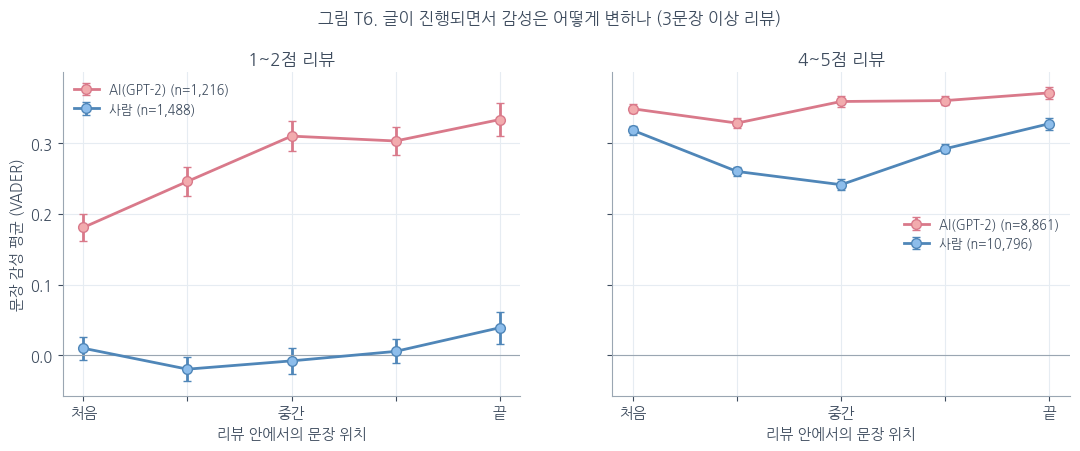

  1~2점 리뷰 위치별 평균 감성:
 group  AI(GPT-2)     사람
pos                    
0          0.181  0.010
1          0.246 -0.020
2          0.310 -0.008
3          0.303  0.006
4          0.333  0.039


In [ ]:
# %% 4. 감성: 문장 위치별 감성 흐름 (T6) ---------------------------------
# 리뷰를 문장으로 나눠, 처음→끝으로 감성이 어떻게 변하는지 봄 (3문장 이상 리뷰만)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
VADER = SentimentIntensityAnalyzer()
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+')

@step
def sentiment_arc():
    """T6 문장 위치별 감성 흐름"""
    rows = []
    for gid, (txt, g, r) in enumerate(zip(df['text_clean'], df['group'], df['rating'])):
        ss = [s for s in SENT_SPLIT.split(txt) if len(s.split()) >= 2]
        if len(ss) < 3: continue
        for i, s in enumerate(ss):
            rows.append((gid, g, r, min(int(5 * i / len(ss)), 4), VADER.polarity_scores(s)['compound']))
    arc = pd.DataFrame(rows, columns=['doc', 'group', 'rating', 'pos', 'vader'])
    arc['별점'] = np.select([arc['rating'] <= 2, arc['rating'] >= 4], ['1~2점', '4~5점'], '3점')
    doc_mean = arc.groupby(['doc', 'group', '별점', 'pos'])['vader'].mean().reset_index()    # 리뷰 한 건이 한 표씩
    summ = doc_mean.groupby(['별점', 'group', 'pos'])['vader'].agg(['mean', 'sem', 'count']).reset_index()
    summ.round(4).to_csv(OUT / 'T6_감성흐름.csv', index=False, encoding='utf-8-sig')
    pos_lab = ['처음', '', '중간', '', '끝']
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
    for ax, star in zip(axs, ['1~2점', '4~5점']):
        for g in GROUPS:
            s = summ[(summ['별점'] == star) & (summ['group'] == g)].sort_values('pos')
            ax.errorbar(s['pos'], s['mean'], yerr=1.96 * s['sem'], marker='o', ms=7, lw=2, capsize=3, color=EDGE[g], mfc=COLORS[g], mec=EDGE[g],
                        label=f"{g} (n={int(s['count'].max()):,})")
        ax.axhline(0, color=NEUTRAL_E, lw=0.8); ax.set_xticks(range(5), pos_lab); ax.set_xlabel('리뷰 안에서의 문장 위치')
        ax.set_title(f'{star} 리뷰'); ax.legend(frameon=False, fontsize=9)
    axs[0].set_ylabel('문장 감성 평균 (VADER)')
    fig.suptitle('그림 T6. 글이 진행되면서 감성은 어떻게 변하나 (3문장 이상 리뷰)', y=1.03, fontsize=12)
    save(fig, 'figT6_감성흐름.png')
    low = summ[summ['별점'] == '1~2점'].pivot(index='pos', columns='group', values='mean')
    print('  1~2점 리뷰 위치별 평균 감성:\n', low.round(3).to_string())
    return low
ARC = sentiment_arc()


===== T7 NRC 8감정 =====
  NRC 사전 단어 6,468개


,감정,AI(GPT-2) (100단어당),사람 (100단어당),효과크기 r
anger,분노,0.730,1.004,-0.156
anticipation,기대,3.352,2.972,-0.011
disgust,혐오,0.468,0.685,-0.138
fear,두려움,0.916,1.130,-0.126
joy,기쁨,3.964,3.218,0.053
sadness,슬픔,0.916,1.160,-0.137
surprise,놀람,1.715,1.486,-0.031
trust,신뢰,3.980,3.547,0.013
positive,긍정,6.578,6.041,0.028
negative,부정,1.899,2.447,-0.178


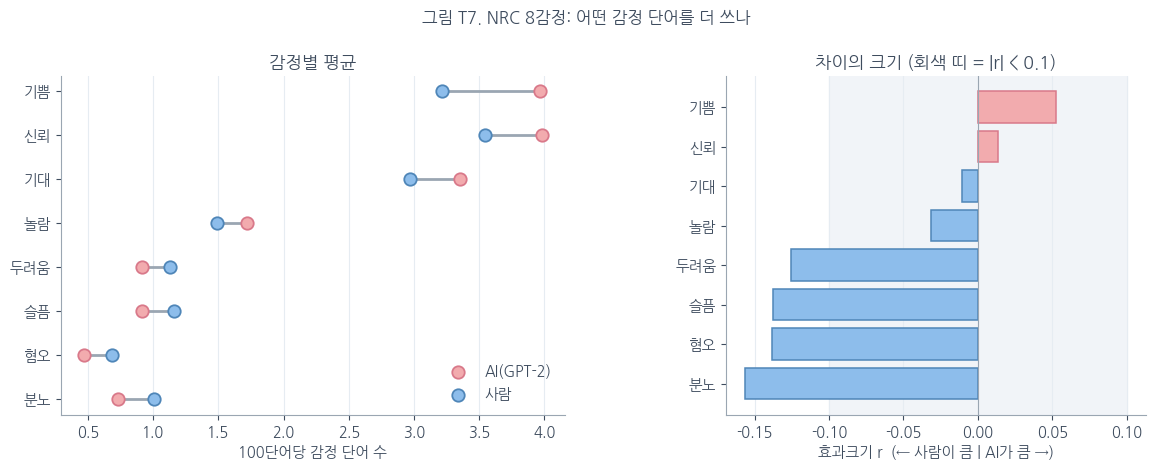

In [ ]:
# %% 5. 감성: NRC 8감정 (T7) ---------------------------------------------
# NRC 감정 사전(Mohammad & Turney, 2013): 단어마다 분노·기대·혐오·두려움·기쁨·슬픔·놀람·신뢰 표시
EMO_KO = {'anger': '분노', 'anticipation': '기대', 'disgust': '혐오', 'fear': '두려움', 'joy': '기쁨', 'sadness': '슬픔',
          'surprise': '놀람', 'trust': '신뢰', 'positive': '긍정', 'negative': '부정'}

def load_nrc():
    import nrclex
    base = os.path.dirname(nrclex.__file__)
    for f in sorted(glob.glob(os.path.join(base, '**', '*.json'), recursive=True)):
        try:
            d = json.load(open(f, encoding='utf-8'))
            if isinstance(d, dict) and len(d) > 1000: return d
        except Exception:
            continue
    from nrclex import NRCLex
    obj = NRCLex('happy')
    for att in ['__lexicon__', 'lexicon', '_NRCLex__lexicon']:
        if isinstance(getattr(obj, att, None), dict): return getattr(obj, att)
    raise RuntimeError('NRC 사전을 찾지 못함')

@step
def nrc_emotions():
    """T7 NRC 8감정"""
    lex = load_nrc(); print(f'  NRC 사전 단어 {len(lex):,}개')
    emos = list(EMO_KO)
    tok = re.compile(r"[a-z]+")
    rows = []
    for t in df['text_clean']:
        ws = tok.findall(t.lower()); n = max(len(ws), 1); c = Counter()
        for w in ws:
            for e in lex.get(w, []): c[e] += 1
        rows.append([100 * c[e] / n for e in emos])
    E = pd.DataFrame(rows, columns=emos)
    tab = pd.DataFrame({'감정': [EMO_KO[e] for e in emos], f'{AI} (100단어당)': E[is_ai].mean().values, f'{HU} (100단어당)': E[~is_ai].mean().values,
                        '효과크기 r': [rb(E.loc[is_ai, e], E.loc[~is_ai, e]) for e in emos]}, index=emos)
    tab.round(4).to_csv(OUT / 'T7_NRC감정.csv', encoding='utf-8-sig'); display(tab.round(3))
    d = tab.loc[emos[:8]].sort_values('효과크기 r')
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1.2, 1], 'wspace': 0.35})
    y = np.arange(len(d))
    for i, g in enumerate(GROUPS):
        col = f'{g} (100단어당)'
        axs[0].scatter(d[col], y, s=80, color=COLORS[g], edgecolor=EDGE[g], linewidth=1.3, zorder=3, label=g)
    for yi, (_, r) in zip(y, d.iterrows()):
        axs[0].plot([r[f'{AI} (100단어당)'], r[f'{HU} (100단어당)']], [yi, yi], color=NEUTRAL_E, lw=2, zorder=2)
    axs[0].set_yticks(y, d['감정']); axs[0].grid(axis='y', visible=False); axs[0].set_xlabel('100단어당 감정 단어 수')
    axs[0].legend(frameon=False, loc='lower right'); axs[0].set_title('감정별 평균')
    axs[1].barh(y, d['효과크기 r'], color=[COLORS[AI] if v > 0 else COLORS[HU] for v in d['효과크기 r']],
                edgecolor=[EDGE[AI] if v > 0 else EDGE[HU] for v in d['효과크기 r']], linewidth=1.1)
    axs[1].axvspan(-0.1, 0.1, color='#F1F4F8', zorder=0); axs[1].axvline(0, color=NEUTRAL_E, lw=0.8)
    axs[1].set_yticks(y, d['감정']); axs[1].grid(axis='y', visible=False); axs[1].set_xlabel('효과크기 r  (← 사람이 큼 | AI가 큼 →)')
    axs[1].set_title('차이의 크기 (회색 띠 = |r| < 0.1)')
    fig.suptitle('그림 T7. NRC 8감정: 어떤 감정 단어를 더 쓰나', y=1.03, fontsize=12)
    save(fig, 'figT7_NRC감정.png')
    return tab
EMO = nrc_emotions()


===== T8 단어 동시출현 네트워크 =====


,노드 수,연결선 수,밀도,평균 군집계수,상위 5개 단어의 연결 강도 점유율
AI(GPT-2),35.0,109.0,0.183,0.216,0.361
사람,37.0,109.0,0.164,0.137,0.360


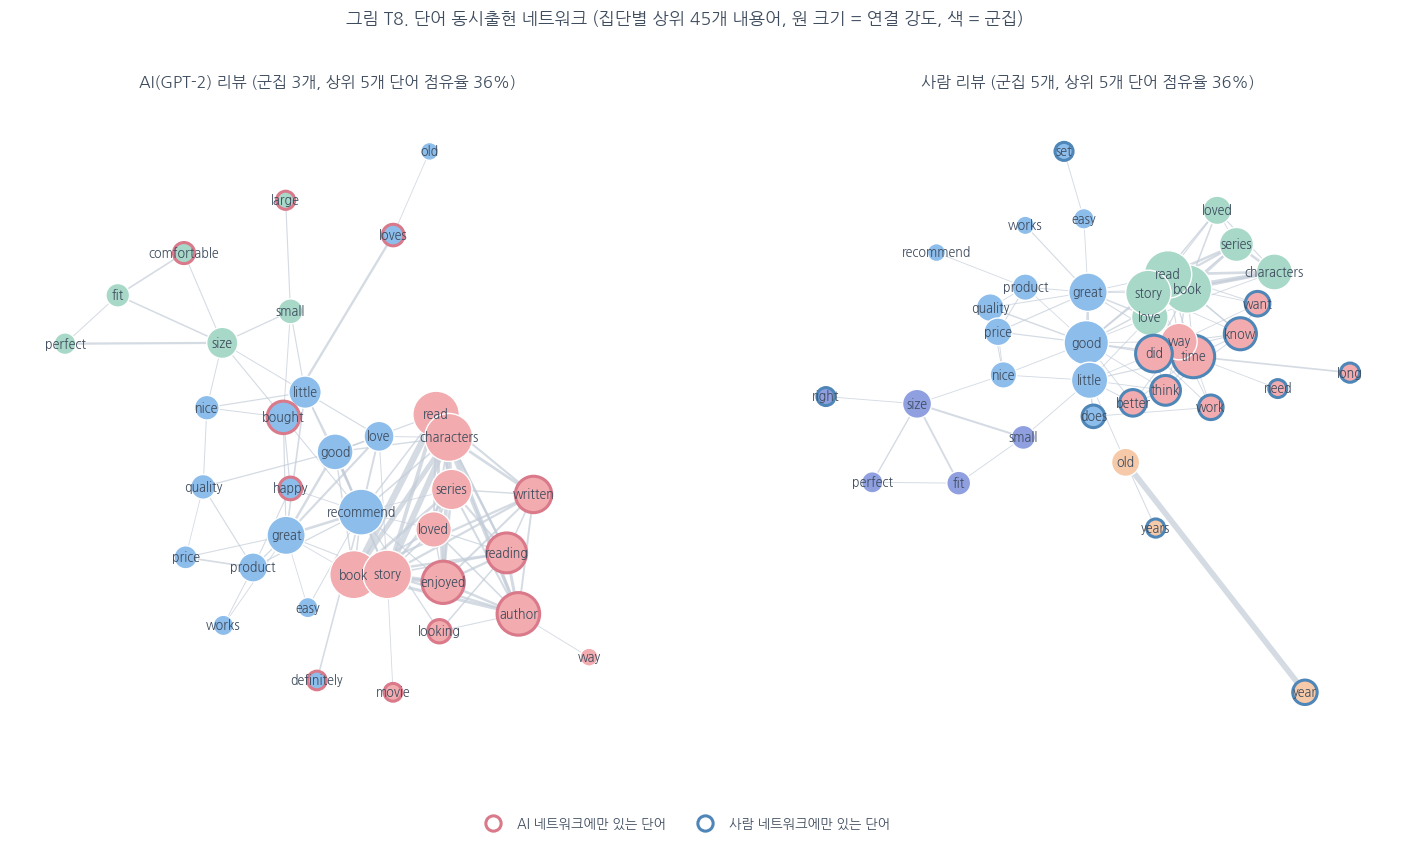


===== T9 중심 단어 비교 =====


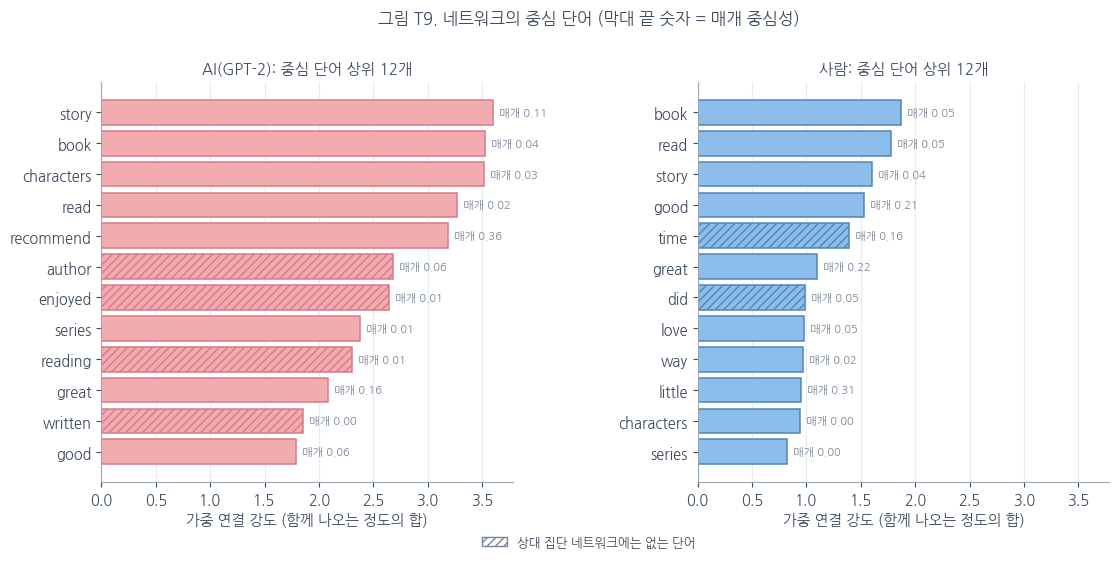

In [ ]:
# %% 6. 관계: 단어 동시출현 네트워크 (T8·T9) ------------------------------
# 같은 리뷰에 함께 나오는 단어끼리 선으로 연결. 집단마다 많이 나오는 내용어 TOP_N개로 네트워크를 만듦
TOP_N = 45      # 집단별 단어 수 (노드)
TOP_E = 110     # 집단별 연결선 수 (가장 강한 것부터)

def build_net(mask):
    sub = Xb[np.where(mask)[0]].tocsc()
    dfr = np.asarray(sub.sum(0)).ravel(); idx = np.argsort(-dfr)[:TOP_N]
    S = sub[:, idx]; C = (S.T @ S).toarray().astype(float); np.fill_diagonal(C, 0)
    n_docs = mask.sum()
    # 연결 강도 = 함께 나온 리뷰 비율. 단순 빈도 효과를 줄이려고 Jaccard(함께/둘 중 하나라도)로 계산
    dd = dfr[idx]; J = C / (dd[:, None] + dd[None, :] - C + 1e-9)
    iu = np.triu_indices(len(idx), 1); w = J[iu]; keep = np.argsort(-w)[:TOP_E]
    G = nx.Graph()
    for k, i in enumerate(idx): G.add_node(vocab_t[i], freq=dfr[i] / n_docs)
    for e in keep:
        a, b = iu[0][e], iu[1][e]
        if w[e] > 0: G.add_edge(vocab_t[idx[a]], vocab_t[idx[b]], weight=float(w[e]))
    G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()   # 가장 큰 덩어리만 (떨어진 조각은 제외)

def net_stats(G):
    wdeg = dict(G.degree(weight='weight')); tot = sum(wdeg.values())
    top5 = sum(sorted(wdeg.values(), reverse=True)[:5]) / tot
    return {'노드 수': G.number_of_nodes(), '연결선 수': G.number_of_edges(), '밀도': nx.density(G),
            '평균 군집계수': nx.average_clustering(G, weight='weight'), '상위 5개 단어의 연결 강도 점유율': top5}

@step
def networks():
    """T8 단어 동시출현 네트워크"""
    nets = {g: build_net((df['group'] == g).values) for g in GROUPS}
    stats = pd.DataFrame({g: net_stats(G) for g, G in nets.items()}).T
    display(stats.round(3)); stats.round(4).to_csv(OUT / 'T8_네트워크_지표.csv', encoding='utf-8-sig')
    only = {AI: set(nets[AI]) - set(nets[HU]), HU: set(nets[HU]) - set(nets[AI])}
    fig, axs = plt.subplots(1, 2, figsize=(18, 8.5))
    cent_rows = []
    for ax, g in zip(axs, GROUPS):
        G = nets[g]
        comms = list(nx.community.greedy_modularity_communities(G, weight='weight'))
        cmap = {n: COMMUNITY[i % len(COMMUNITY)] for i, c in enumerate(comms) for n in c}
        pos = nx.kamada_kawai_layout(G)          # 연결 단계(몇 다리 건너인지)를 거리로 써서 고르게 펼침
        wdeg = dict(G.degree(weight='weight')); mx = max(wdeg.values())
        ws = np.array([G[u][v]['weight'] for u, v in G.edges]); ws = 0.6 + 4 * (ws - ws.min()) / (ws.max() - ws.min() + 1e-9)
        nx.draw_networkx_edges(G, pos, ax=ax, width=ws, edge_color='#C3CCD8', alpha=0.7)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[120 + 1100 * wdeg[n] / mx for n in G],
                               node_color=[cmap[n] for n in G], edgecolors=[EDGE[g] if n in only[g] else '#FFFFFF' for n in G],
                               linewidths=[2.2 if n in only[g] else 1.0 for n in G])
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_family=plt.rcParams['font.family'][0] if isinstance(plt.rcParams['font.family'], list) else plt.rcParams['font.family'], font_color=INK)
        ax.set_title(f"{g} 리뷰 (군집 {len(comms)}개, 상위 5개 단어 점유율 {stats.loc[g, '상위 5개 단어의 연결 강도 점유율']:.0%})", fontsize=11.5)
        ax.axis('off')
        deg = nx.degree_centrality(G); btw = nx.betweenness_centrality(G, weight=None)
        try: eig = nx.eigenvector_centrality(G, weight='weight', max_iter=2000)
        except Exception: eig = {n: np.nan for n in G}
        for n in G: cent_rows.append({'집단': g, '단어': n, '연결 중심성': deg[n], '매개 중심성': btw[n], '고유벡터 중심성': eig[n],
                                      '가중 연결 강도': wdeg[n], '등장 비율': G.nodes[n]['freq'], '이 집단에만 있음': n in only[g]})
    fig.legend(handles=[Line2D([], [], marker='o', ls='', mfc='white', mec=EDGE[AI], mew=2.2, ms=11, label='AI 네트워크에만 있는 단어'),
                        Line2D([], [], marker='o', ls='', mfc='white', mec=EDGE[HU], mew=2.2, ms=11, label='사람 네트워크에만 있는 단어')],
               loc='lower center', ncol=2, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f'그림 T8. 단어 동시출현 네트워크 (집단별 상위 {TOP_N}개 내용어, 원 크기 = 연결 강도, 색 = 군집)', y=0.98, fontsize=12.5)
    save(fig, 'figT8_네트워크.png')
    cent = pd.DataFrame(cent_rows); cent.round(4).to_csv(OUT / 'T9_중심성.csv', index=False, encoding='utf-8-sig')
    return nets, stats, cent, only
NET = networks()

@step
def centrality_plot():
    """T9 중심 단어 비교"""
    nets, stats, cent, only = NET
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, gridspec_kw={'wspace': 0.45})   # 같은 눈금으로 비교
    for ax, g in zip(axs, GROUPS):
        d = cent[cent['집단'] == g].sort_values('가중 연결 강도', ascending=False).head(12).iloc[::-1]
        ax.barh(d['단어'], d['가중 연결 강도'], color=COLORS[g], edgecolor=EDGE[g], linewidth=1.1,
                hatch=['////' if o else '' for o in d['이 집단에만 있음']])
        for yi, (_, r) in enumerate(d.iterrows()):
            ax.text(r['가중 연결 강도'], yi, f"  매개 {r['매개 중심성']:.2f}", va='center', fontsize=8, color=INK2)
        ax.grid(axis='y', visible=False); ax.set_xlabel('가중 연결 강도 (함께 나오는 정도의 합)')
        ax.set_title(f'{g}: 중심 단어 상위 12개', fontsize=11)
    fig.legend(handles=[Patch(facecolor='white', edgecolor=INK2, hatch='////', label='상대 집단 네트워크에는 없는 단어')],
               loc='lower center', frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.04))
    fig.suptitle('그림 T9. 네트워크의 중심 단어 (막대 끝 숫자 = 매개 중심성)', y=1.02, fontsize=12)
    save(fig, 'figT9_중심단어.png')
centrality_plot()

In [ ]:
# %% 7. 가설 정리와 저장 -------------------------------------------------
lines = ['# 텍스트마이닝 핵심 결과 (GPT-2 AI vs 사람)', f'- 리뷰 {len(df):,}건 ({AI} {N[AI]:,} / {HU} {N[HU]:,})']
if LEX is not None:
    lines += ['- [어휘] AI 쪽 특징 단어: ' + ', '.join(LEX.head(12)['단어']), '- [어휘] 사람 쪽 특징 단어: ' + ', '.join(LEX.tail(12)['단어'][::-1])]
if CLICHE: lines.append(f"- [표현] 상투구 비율 중앙값 {AI} {CLICHE['상투구 중앙값 AI']:.3f} vs {HU} {CLICHE['상투구 중앙값 사람']:.3f} (r = {CLICHE['r']:+.2f})")
if TOPICS is not None:
    tt = TOPICS[0]
    lines += [f'- [주제] LDA K = {K}',
              '  - AI 리뷰에 많은 주제: ' + '; '.join(f"{r['토픽']}({r['상위 단어']}) {r['차이(AI-사람, %p)']:+.1f}%p" for _, r in tt.head(2).iterrows()),
              '  - 사람 리뷰에 많은 주제: ' + '; '.join(f"{r['토픽']}({r['상위 단어']}) {r['차이(AI-사람, %p)']:+.1f}%p" for _, r in tt.tail(2).iloc[::-1].iterrows())]
if DIVERSITY: lines.append(f"- [주제 다양성] 중앙값 {AI} {DIVERSITY['중앙값 AI']:.3f} vs {HU} {DIVERSITY['중앙값 사람']:.3f} (r = {DIVERSITY['r']:+.2f}), 길이 구간별 r = {DIVERSITY['길이별 r']}")
if ARC is not None:
    lines.append(f"- [감성 흐름] 1~2점 리뷰의 끝 문장 평균 감성: {AI} {ARC.loc[4, AI]:+.3f} vs {HU} {ARC.loc[4, HU]:+.3f}, 처음 문장: {AI} {ARC.loc[0, AI]:+.3f} vs {HU} {ARC.loc[0, HU]:+.3f}")
if EMO is not None:
    big = EMO[EMO['효과크기 r'].abs() >= 0.1]
    lines.append('- [감정] |r| ≥ 0.1인 감정: ' + (', '.join(f"{r['감정']}({r['효과크기 r']:+.2f})" for _, r in big.iterrows()) or '없음'))
if NET is not None:
    st = NET[1]
    lines.append(f"- [네트워크] 상위 5개 단어 점유율 {AI} {st.loc[AI, '상위 5개 단어의 연결 강도 점유율']:.1%} vs {HU} {st.loc[HU, '상위 5개 단어의 연결 강도 점유율']:.1%}, "
                 f"밀도 {st.loc[AI, '밀도']:.3f} vs {st.loc[HU, '밀도']:.3f}")
    lines.append('  - AI 네트워크에만 있는 단어: ' + ', '.join(sorted(NET[3][AI])))
    lines.append('  - 사람 네트워크에만 있는 단어: ' + ', '.join(sorted(NET[3][HU])))
lines.append(f'- 실패한 분석: {", ".join(FAILED) if FAILED else "없음"}')
(OUT / '00_핵심결과_요약.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
keep = ['review_id', 'group', 'category', 'rating'] + [c for c in df.columns if c.startswith('topic_') or c == 'cliche_ratio']
df[keep].to_csv(OUT / '리뷰별_토픽_상투구.csv', index=False, encoding='utf-8-sig')

zip_path = Path('텍스트마이닝_결과.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()): z.write(f, arcname=f'textmining_results/{f.name}')
print('\n저장 완료:', zip_path, f'({zip_path.stat().st_size / 1e6:.1f} MB)')
if IN_COLAB:
    files.download(str(zip_path))

# 텍스트마이닝 핵심 결과 (GPT-2 AI vs 사람)
- 리뷰 40,214건 (AI(GPT-2) 20,052 / 사람 20,162)
- [어휘] AI 쪽 특징 단어: is, very, great, the, good, it, book, recommend, characters, story, movie, loves
- [어휘] 사람 쪽 특징 단어: at, or, when, you, as, on, even, out, all, after, in, up
- [표현] 상투구 비율 중앙값 AI(GPT-2) 0.283 vs 사람 0.061 (r = +0.70)
- [주제] LDA K = 6
  - AI 리뷰에 많은 주제: 토픽 4(great, light, works, easy, product, good) +6.7%p; 토픽 1(size, fit, great, comfortable, love, little) +6.1%p
  - 사람 리뷰에 많은 주제: 토픽 6(time, work, does, new, better, did) -15.3%p; 토픽 5(easy, water, little, box, good, plastic) -7.9%p
- [주제 다양성] 중앙값 AI(GPT-2) 0.402 vs 사람 0.499 (r = -0.29), 길이 구간별 r = [-0.129, -0.243, -0.412, -0.493]
- [감성 흐름] 1~2점 리뷰의 끝 문장 평균 감성: AI(GPT-2) +0.333 vs 사람 +0.039, 처음 문장: AI(GPT-2) +0.181 vs 사람 +0.010
- [감정] |r| ≥ 0.1인 감정: 분노(-0.16), 혐오(-0.14), 두려움(-0.13), 슬픔(-0.14), 부정(-0.18)
- [네트워크] 상위 5개 단어 점유율 AI(GPT-2) 36.1% vs 사람 36.0%, 밀도 0.183 vs 0.164
  - AI 네트워크에만 있는 단어: author, bought, comfortable, definitely, enjoyed, happy,

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

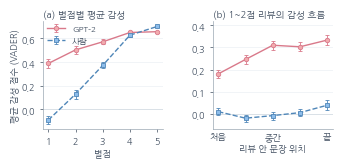

그림 1 저장: 논문_그림1_감성정합성.png
  (a) 별점별 평균 감성:
rating       1.0    2.0    3.0    4.0    5.0
group                                       
AI(GPT-2)  0.389  0.503  0.572  0.650  0.657
사람        -0.090  0.129  0.373  0.628  0.701
  (b) 1~2점 3문장 이상 리뷰 수: GPT-2 1,216건, 사람 1,488건


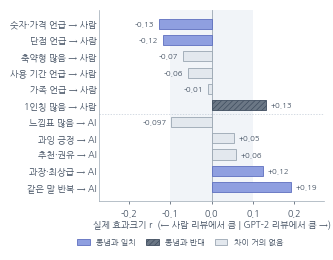

그림 2 저장: 논문_그림2_통념비교.png
  판정 요약: {'차이 거의 없음': 6, '통념과 일치': 4, '통념과 반대': 1}

[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 1) 별점과 리뷰 감성의 정합성: (a) 별점별 평균 감성 점수, (b) 1~2점 리뷰의 문장 위치별 평균 감성 (오차 막대는 95% 신뢰구간)
(그림 2) 사람의 판별 통념과 실제 데이터의 비교 (회색 띠는 |r| < 0.1, 차이가 작은 구간)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% 9. 논문용 그림 최종본 (그림 1: 감성 정합성 2칸, 그림 2: 통념 vs 데이터) -------------
# 텍스트마이닝 노트북의 셀 0~7을 실행한 다음, 맨 끝에 이 셀을 붙여서 실행
# - 학회 양식 2단의 한 단 너비(85mm)에 맞춤, 600dpi PNG
# - 그림 안에 제목 없음 (한글 양식에서 "(그림 1) 제목"을 그림 아래에 따로 붙이기)
# - 흑백 인쇄 대비: AI = 실선 + 동그라미, 사람 = 점선 + 네모
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

PAPER_RC = {'font.size': 6.5, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
            'xtick.major.size': 2, 'ytick.major.size': 2, 'axes.spines.top': False, 'axes.spines.right': False,
            'axes.grid': False, 'axes.edgecolor': '#9AA6B2', 'text.color': '#3E4C5E', 'axes.labelcolor': '#3E4C5E',
            'xtick.color': '#3E4C5E', 'ytick.color': '#3E4C5E', 'axes.unicode_minus': False, 'hatch.linewidth': 0.5,
            'savefig.dpi': 600, 'legend.frameon': False}
if KFONT:
    PAPER_RC['font.family'] = KFONT
STYLE = {AI: dict(color=EDGE[AI], mfc=COLORS[AI], mec=EDGE[AI], marker='o', ls='-', label='GPT-2'),
         HU: dict(color=EDGE[HU], mfc=COLORS[HU], mec=EDGE[HU], marker='s', ls='--', label='사람')}
LINE_KW = dict(ms=3.2, lw=1.0, capsize=1.5, elinewidth=0.6, mew=0.6)

# ---------------- 그림 1: (a) 별점별 평균 감성  (b) 1~2점 리뷰의 문장 위치별 감성 ----------------
assert {'vader', 'rating'} <= set(df.columns), 'df에 vader·rating 열이 없어요. 텍스트마이닝 노트북 셀 0부터 다시 실행하세요.'
star = (df.groupby(['group', 'rating'])['vader'].agg(['mean', 'sem', 'count']).reset_index())
arc = pd.read_csv(OUT / 'T6_감성흐름.csv')
low = arc[arc['별점'] == '1~2점'].sort_values('pos')
with plt.rc_context(PAPER_RC):
    fig, (axa, axb) = plt.subplots(1, 2, figsize=(3.35, 1.55),
                                   gridspec_kw=dict(wspace=0.42, left=0.12, right=0.985, top=0.9, bottom=0.2))
    for g in GROUPS:
        s = star[star['group'] == g].sort_values('rating')
        axa.errorbar(s['rating'], s['mean'], yerr=1.96 * s['sem'], **STYLE[g], **LINE_KW)
        s = low[low['group'] == g]
        axb.errorbar(s['pos'], s['mean'], yerr=1.96 * s['sem'], **STYLE[g], **LINE_KW)
    for ax in (axa, axb):
        ax.axhline(0, color='#B8C2CC', lw=0.5, zorder=0)
        ax.grid(axis='y', color='#E6ECF2', lw=0.4)
    axa.set_xticks([1, 2, 3, 4, 5]); axa.set_xlabel('별점', labelpad=1.5); axa.set_ylabel('평균 감성 점수 (VADER)', labelpad=1.5)
    axa.set_title('(a) 별점별 평균 감성', fontsize=6.8, loc='left', pad=3)
    axa.legend(loc='upper left', fontsize=6, handlelength=2.2, borderaxespad=0.1)
    axb.set_xticks(range(5), ['처음', '', '중간', '', '끝']); axb.tick_params(axis='x', length=0, pad=2)
    axb.set_xlabel('리뷰 안 문장 위치', labelpad=1.5)
    axb.set_title('(b) 1~2점 리뷰의 감성 흐름', fontsize=6.8, loc='left', pad=3)
    lo_y = min(-0.05, low['mean'].min() - 0.05)
    axb.set_ylim(lo_y, max(0.42, low['mean'].max() + 0.08))
    fig.savefig(OUT / '논문_그림1_감성정합성.png', facecolor='white')
    plt.show(); plt.close(fig)
n_low = low.groupby('group')['count'].max()
print('그림 1 저장: 논문_그림1_감성정합성.png')
print('  (a) 별점별 평균 감성:'); print(star.pivot(index='group', columns='rating', values='mean').round(3).to_string())
print(f"  (b) 1~2점 3문장 이상 리뷰 수: GPT-2 {int(n_low.get(AI, 0)):,}건, 사람 {int(n_low.get(HU, 0)):,}건")

# ---------------- 그림 2: 사람의 통념 vs 실제 데이터 ----------------
SHORT = {'1인칭(I·my)이 많으면 사람': '1인칭 많음 → 사람', '가족 이야기가 있으면 사람': '가족 언급 → 사람',
         '사용 기간 등 경험담이 있으면 사람': '사용 기간 언급 → 사람', '축약형(구어체)이 많으면 사람': '축약형 많음 → 사람',
         '숫자·가격 등 구체적이면 사람': '숫자·가격 언급 → 사람', '단점도 말하면 사람': '단점 언급 → 사람',
         '과장·최상급이 많으면 AI': '과장·최상급 → AI', '추천·권유가 많으면 AI': '추천·권유 → AI',
         '느낌표가 많으면 AI': '느낌표 많음 → AI', '같은 말을 반복하면 AI': '같은 말 반복 → AI',
         '지나치게 긍정적이면 AI': '과잉 긍정 → AI'}
VERDICT = {'통념과 일치': (PERI, PERI_E, ''), '통념과 반대': ('#6B7785', '#3E4C5E', '//////'),
           '차이 거의 없음': ('#E3E8EE', '#9AA6B2', '')}
bel_path = next((p for p in [DATA_DIR / '10_통념점검.csv', Path('10_통념점검.csv')] if p.exists()), None)
assert bel_path is not None, '10_통념점검.csv가 없어요. EDA_v2_결과.zip을 다시 업로드하세요.'
bel = pd.read_csv(bel_path).drop(columns=[c for c in ['Unnamed: 0'] if c in pd.read_csv(bel_path).columns])
bel['짧은 이름'] = bel['통념'].map(SHORT).fillna(bel['통념'])
bel['순서'] = np.where(bel['통념상 큰 쪽'] == HU, 0, 1)        # 위쪽: "→ 사람" 통념, 아래쪽: "→ AI" 통념
bel = bel.sort_values(['순서', '실제 효과크기 r']).reset_index(drop=True)
with plt.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(3.35, 2.45))
    fig.subplots_adjust(left=0.3, right=0.97, top=0.98, bottom=0.2)
    yy = np.arange(len(bel))[::-1]
    ax.axvspan(-0.1, 0.1, color='#F1F4F8', zorder=0, lw=0)
    ax.axvline(0, color='#9AA6B2', lw=0.6, zorder=1)
    for yi, (_, r) in zip(yy, bel.iterrows()):
        fc, ec, ht = VERDICT.get(r['판정'], VERDICT['차이 거의 없음'])
        v = r['실제 효과크기 r']
        ax.barh(yi, v, height=0.62, color=fc, edgecolor=ec, linewidth=0.6, hatch=ht, zorder=2)
        lab = f'{v:+.3f}' if abs(v) < 0.1 and round(abs(v), 2) >= 0.1 else f'{v:+.2f}'   # -0.097이 -0.10으로 보여 기준과 헷갈리지 않게
        ax.text(v + (0.012 if v >= 0 else -0.012), yi, lab, va='center', ha='left' if v >= 0 else 'right', fontsize=5.6)
    n_hu = int((bel['순서'] == 0).sum())
    ax.axhline(yy[n_hu - 1] - 0.5, color='#C3CCD8', lw=0.5, ls=(0, (2, 2)))   # "→ 사람" / "→ AI" 경계
    ax.set_yticks(yy, bel['짧은 이름']); ax.tick_params(axis='y', length=0, pad=2)
    lim = max(0.25, bel['실제 효과크기 r'].abs().max() + 0.08)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel('실제 효과크기 r  (← 사람 리뷰에서 큼 | GPT-2 리뷰에서 큼 →)', labelpad=2)
    ax.legend(handles=[Patch(facecolor=VERDICT[k][0], edgecolor=VERDICT[k][1], hatch=VERDICT[k][2], lw=0.6, label=k)
                       for k in ['통념과 일치', '통념과 반대', '차이 거의 없음']],
              loc='upper center', bbox_to_anchor=(0.36, -0.16), ncol=3, fontsize=5.8, handlelength=1.6, columnspacing=1.2)
    fig.savefig(OUT / '논문_그림2_통념비교.png', facecolor='white')
    plt.show(); plt.close(fig)
print('그림 2 저장: 논문_그림2_통념비교.png')
print('  판정 요약:', bel['판정'].value_counts().to_dict())

print('''
[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 1) 별점과 리뷰 감성의 정합성: (a) 별점별 평균 감성 점수, (b) 1~2점 리뷰의 문장 위치별 평균 감성 (오차 막대는 95% 신뢰구간)
(그림 2) 사람의 판별 통념과 실제 데이터의 비교 (회색 띠는 |r| < 0.1, 차이가 작은 구간)
''')
import zipfile
zp = Path('논문그림_최종.zip')
with zipfile.ZipFile(zp, 'w') as z:
    for n in ['논문_그림1_감성정합성.png', '논문_그림2_통념비교.png']:
        z.write(OUT / n, arcname=n)
if IN_COLAB:
    files.download(str(zp))

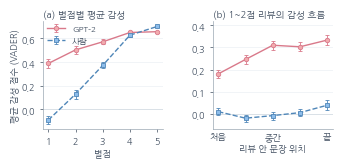

그림 1 저장: 논문_그림1_감성정합성.png
  (a) 별점별 평균 감성:
rating       1.0    2.0    3.0    4.0    5.0
group                                       
AI(GPT-2)  0.389  0.503  0.572  0.650  0.657
사람        -0.090  0.129  0.373  0.628  0.701
  (b) 1~2점 3문장 이상 리뷰 수: GPT-2 1,216건, 사람 1,488건


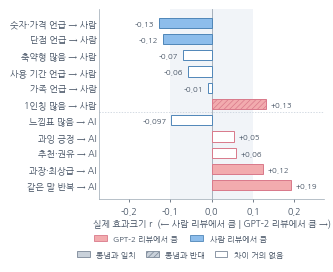

그림 2 저장: 논문_그림2_통념비교.png
  판정 요약: {'차이 거의 없음': 6, '통념과 일치': 4, '통념과 반대': 1}

[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 1) 별점과 리뷰 감성의 정합성: (a) 별점별 평균 감성 점수, (b) 1~2점 리뷰의 문장 위치별 평균 감성 (오차 막대는 95% 신뢰구간)
(그림 2) 사람의 판별 통념과 실제 데이터의 비교 (색은 실제로 더 큰 쪽, 회색 띠는 |r| < 0.1인 구간)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% 9. 논문용 그림 최종본 (그림 1: 감성 정합성 2칸, 그림 2: 통념 vs 데이터) -------------
# 텍스트마이닝 노트북의 셀 0~7을 실행한 다음, 맨 끝에 이 셀을 붙여서 실행
# - 학회 양식 2단의 한 단 너비(85mm)에 맞춤, 600dpi PNG
# - 그림 안에 제목 없음 (한글 양식에서 "(그림 1) 제목"을 그림 아래에 따로 붙이기)
# - 색: 사람 = 파랑, AI = 분홍 / 흑백 인쇄 대비: AI = 실선 + 동그라미, 사람 = 점선 + 네모
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

PAPER_RC = {'font.size': 6.5, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
            'xtick.major.size': 2, 'ytick.major.size': 2, 'axes.spines.top': False, 'axes.spines.right': False,
            'axes.grid': False, 'axes.edgecolor': '#9AA6B2', 'text.color': '#3E4C5E', 'axes.labelcolor': '#3E4C5E',
            'xtick.color': '#3E4C5E', 'ytick.color': '#3E4C5E', 'axes.unicode_minus': False, 'hatch.linewidth': 0.5,
            'savefig.dpi': 600, 'legend.frameon': False}
if KFONT:
    PAPER_RC['font.family'] = KFONT
STYLE = {AI: dict(color=EDGE[AI], mfc=COLORS[AI], mec=EDGE[AI], marker='o', ls='-', label='GPT-2'),
         HU: dict(color=EDGE[HU], mfc=COLORS[HU], mec=EDGE[HU], marker='s', ls='--', label='사람')}
LINE_KW = dict(ms=3.2, lw=1.0, capsize=1.5, elinewidth=0.6, mew=0.6)

# ---------------- 그림 1: (a) 별점별 평균 감성  (b) 1~2점 리뷰의 문장 위치별 감성 ----------------
assert {'vader', 'rating'} <= set(df.columns), 'df에 vader·rating 열이 없어요. 텍스트마이닝 노트북 셀 0부터 다시 실행하세요.'
star = (df.groupby(['group', 'rating'])['vader'].agg(['mean', 'sem', 'count']).reset_index())
arc = pd.read_csv(OUT / 'T6_감성흐름.csv')
low = arc[arc['별점'] == '1~2점'].sort_values('pos')
with plt.rc_context(PAPER_RC):
    fig, (axa, axb) = plt.subplots(1, 2, figsize=(3.35, 1.55),
                                   gridspec_kw=dict(wspace=0.42, left=0.12, right=0.985, top=0.9, bottom=0.2))
    for g in GROUPS:
        s = star[star['group'] == g].sort_values('rating')
        axa.errorbar(s['rating'], s['mean'], yerr=1.96 * s['sem'], **STYLE[g], **LINE_KW)
        s = low[low['group'] == g]
        axb.errorbar(s['pos'], s['mean'], yerr=1.96 * s['sem'], **STYLE[g], **LINE_KW)
    for ax in (axa, axb):
        ax.axhline(0, color='#B8C2CC', lw=0.5, zorder=0)
        ax.grid(axis='y', color='#E6ECF2', lw=0.4)
    axa.set_xticks([1, 2, 3, 4, 5]); axa.set_xlabel('별점', labelpad=1.5); axa.set_ylabel('평균 감성 점수 (VADER)', labelpad=1.5)
    axa.set_title('(a) 별점별 평균 감성', fontsize=6.8, loc='left', pad=3)
    axa.legend(loc='upper left', fontsize=6, handlelength=2.2, borderaxespad=0.1)
    axb.set_xticks(range(5), ['처음', '', '중간', '', '끝']); axb.tick_params(axis='x', length=0, pad=2)
    axb.set_xlabel('리뷰 안 문장 위치', labelpad=1.5)
    axb.set_title('(b) 1~2점 리뷰의 감성 흐름', fontsize=6.8, loc='left', pad=3)
    lo_y = min(-0.05, low['mean'].min() - 0.05)
    axb.set_ylim(lo_y, max(0.42, low['mean'].max() + 0.08))
    fig.savefig(OUT / '논문_그림1_감성정합성.png', facecolor='white')
    plt.show(); plt.close(fig)
n_low = low.groupby('group')['count'].max()
print('그림 1 저장: 논문_그림1_감성정합성.png')
print('  (a) 별점별 평균 감성:'); print(star.pivot(index='group', columns='rating', values='mean').round(3).to_string())
print(f"  (b) 1~2점 3문장 이상 리뷰 수: GPT-2 {int(n_low.get(AI, 0)):,}건, 사람 {int(n_low.get(HU, 0)):,}건")

# ---------------- 그림 2: 사람의 통념 vs 실제 데이터 ----------------
SHORT = {'1인칭(I·my)이 많으면 사람': '1인칭 많음 → 사람', '가족 이야기가 있으면 사람': '가족 언급 → 사람',
         '사용 기간 등 경험담이 있으면 사람': '사용 기간 언급 → 사람', '축약형(구어체)이 많으면 사람': '축약형 많음 → 사람',
         '숫자·가격 등 구체적이면 사람': '숫자·가격 언급 → 사람', '단점도 말하면 사람': '단점 언급 → 사람',
         '과장·최상급이 많으면 AI': '과장·최상급 → AI', '추천·권유가 많으면 AI': '추천·권유 → AI',
         '느낌표가 많으면 AI': '느낌표 많음 → AI', '같은 말을 반복하면 AI': '같은 말 반복 → AI',
         '지나치게 긍정적이면 AI': '과잉 긍정 → AI'}
# 색 = 실제로 더 큰 쪽 (분홍 = GPT-2, 파랑 = 사람), 모양 = 판정 (채움 = 일치, 빗금 = 반대, 테두리만 = 차이 거의 없음)
def bar_style(v, verdict):
    side = AI if v > 0 else HU
    if verdict == '통념과 일치':
        return dict(color=COLORS[side], edgecolor=EDGE[side], hatch='')
    if verdict == '통념과 반대':
        return dict(color=COLORS[side], edgecolor=EDGE[side], hatch='//////')
    return dict(color='white', edgecolor=EDGE[side], hatch='')
bel_path = next((p for p in [DATA_DIR / '10_통념점검.csv', Path('10_통념점검.csv')] if p.exists()), None)
assert bel_path is not None, '10_통념점검.csv가 없어요. EDA_v2_결과.zip을 다시 업로드하세요.'
bel = pd.read_csv(bel_path).drop(columns=[c for c in ['Unnamed: 0'] if c in pd.read_csv(bel_path).columns])
bel['짧은 이름'] = bel['통념'].map(SHORT).fillna(bel['통념'])
bel['순서'] = np.where(bel['통념상 큰 쪽'] == HU, 0, 1)        # 위쪽: "→ 사람" 통념, 아래쪽: "→ AI" 통념
bel = bel.sort_values(['순서', '실제 효과크기 r']).reset_index(drop=True)
with plt.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(3.35, 2.6))
    fig.subplots_adjust(left=0.3, right=0.97, top=0.98, bottom=0.25)
    yy = np.arange(len(bel))[::-1]
    ax.axvspan(-0.1, 0.1, color='#F1F4F8', zorder=0, lw=0)
    ax.axvline(0, color='#9AA6B2', lw=0.6, zorder=1)
    for yi, (_, r) in zip(yy, bel.iterrows()):
        v = r['실제 효과크기 r']
        ax.barh(yi, v, height=0.62, linewidth=0.7, zorder=2, **bar_style(v, r['판정']))
        lab = f'{v:+.3f}' if abs(v) < 0.1 and round(abs(v), 2) >= 0.1 else f'{v:+.2f}'   # -0.097이 -0.10으로 보여 기준과 헷갈리지 않게
        ax.text(v + (0.012 if v >= 0 else -0.012), yi, lab, va='center', ha='left' if v >= 0 else 'right', fontsize=5.6)
    n_hu = int((bel['순서'] == 0).sum())
    ax.axhline(yy[n_hu - 1] - 0.5, color='#C3CCD8', lw=0.5, ls=(0, (2, 2)))   # "→ 사람" / "→ AI" 경계
    ax.set_yticks(yy, bel['짧은 이름']); ax.tick_params(axis='y', length=0, pad=2)
    lim = max(0.25, bel['실제 효과크기 r'].abs().max() + 0.08)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel('실제 효과크기 r  (← 사람 리뷰에서 큼 | GPT-2 리뷰에서 큼 →)', labelpad=2)
    leg1 = ax.legend(handles=[Patch(facecolor=COLORS[AI], edgecolor=EDGE[AI], lw=0.6, label='GPT-2 리뷰에서 큼'),
                              Patch(facecolor=COLORS[HU], edgecolor=EDGE[HU], lw=0.6, label='사람 리뷰에서 큼')],
                     loc='upper center', bbox_to_anchor=(0.36, -0.15), ncol=2, fontsize=5.8, handlelength=1.6, columnspacing=1.5)
    ax.add_artist(leg1)
    ax.legend(handles=[Patch(facecolor='#C9D1DA', edgecolor='#7A8797', lw=0.6, label='통념과 일치'),
                       Patch(facecolor='#C9D1DA', edgecolor='#7A8797', hatch='//////', lw=0.6, label='통념과 반대'),
                       Patch(facecolor='white', edgecolor='#7A8797', lw=0.6, label='차이 거의 없음')],
              loc='upper center', bbox_to_anchor=(0.36, -0.235), ncol=3, fontsize=5.8, handlelength=1.6, columnspacing=1.2)
    fig.savefig(OUT / '논문_그림2_통념비교.png', facecolor='white')
    plt.show(); plt.close(fig)
print('그림 2 저장: 논문_그림2_통념비교.png')
print('  판정 요약:', bel['판정'].value_counts().to_dict())

print('''
[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 1) 별점과 리뷰 감성의 정합성: (a) 별점별 평균 감성 점수, (b) 1~2점 리뷰의 문장 위치별 평균 감성 (오차 막대는 95% 신뢰구간)
(그림 2) 사람의 판별 통념과 실제 데이터의 비교 (색은 실제로 더 큰 쪽, 회색 띠는 |r| < 0.1인 구간)
''')
import zipfile
zp = Path('논문그림_최종.zip')
with zipfile.ZipFile(zp, 'w') as z:
    for n in ['논문_그림1_감성정합성.png', '논문_그림2_통념비교.png']:
        z.write(OUT / n, arcname=n)
if IN_COLAB:
    files.download(str(zp))

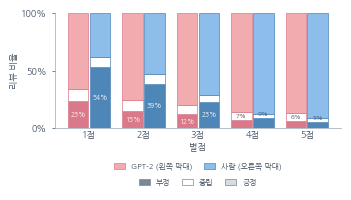

그림 저장: 논문_그림_감성구성.png
별점별 글 감성 구성 (%):
          GPT-2                사람           
vader_cat    부정    중립    긍정    부정   중립    긍정
rating                                      
1          23.3  11.1  65.5  53.6  7.9  38.5
2          15.2   9.5  75.3  38.6  8.6  52.8
3          12.1   8.1  79.9  22.9  5.6  71.6
4           7.3   6.8  85.9   9.1  3.2  87.7
5           5.9   7.1  87.0   5.3  3.3  91.4

[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 3) 별점별 리뷰 감성 구성 (VADER ≥ 0.05 긍정, ≤ -0.05 부정, 숫자는 부정 비율)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% 10. 논문용 그림: 별점별 리뷰 감성 구성 (EDA 그림 8 오른쪽 칸의 논문용 버전) -----------
# 셀 9를 실행한 다음 붙여서 실행 (셀 9의 PAPER_RC를 그대로 씀)
# - 감성 구분은 EDA와 같음: VADER ≥ 0.05 긍정, ≤ -0.05 부정, 그 사이 중립
# - 색 = 집단 (GPT-2 분홍, 사람 파랑), 진하기 = 감성 (진한 색 = 부정, 흰색 = 중립, 연한 색 = 긍정)
# - 숫자 = 그 별점에서 글이 부정인 비율
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

df['vader_cat'] = np.select([df['vader'] >= 0.05, df['vader'] <= -0.05], ['긍정', '부정'], '중립')
comp = {g: pd.crosstab(df.loc[df['group'] == g, 'rating'], df.loc[df['group'] == g, 'vader_cat'], normalize='index')
              .reindex(index=[1, 2, 3, 4, 5], columns=['부정', '중립', '긍정'], fill_value=0) for g in GROUPS}
SEG = {'부정': lambda g: dict(color=EDGE[g], edgecolor=EDGE[g]),
       '중립': lambda g: dict(color='white', edgecolor=EDGE[g]),
       '긍정': lambda g: dict(color=COLORS[g], edgecolor=EDGE[g])}
with plt.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(3.35, 1.95))
    fig.subplots_adjust(left=0.13, right=0.985, top=0.95, bottom=0.36)
    x = np.arange(1, 6); w = 0.38
    for i, g in enumerate(GROUPS):
        xs = x + (i - 0.5) * w * 1.06
        bottom = np.zeros(5)
        for cat in ['부정', '중립', '긍정']:
            v = comp[g][cat].values
            ax.bar(xs, v, w, bottom=bottom, linewidth=0.5, zorder=2, **SEG[cat](g))
            bottom += v
        for xi, neg in zip(xs, comp[g]['부정'].values):      # 부정 비율 숫자: 칸이 충분하면 진한 칸 안(흰 글씨), 아니면 칸 바로 위
            if neg >= 0.12:
                ax.text(xi, neg / 2, f'{neg:.0%}', ha='center', va='center', fontsize=4.8, color='white', fontweight='bold', zorder=3)
            else:
                ax.text(xi, neg + 0.012, f'{neg:.0%}', ha='center', va='bottom', fontsize=4.6, color='#3E4C5E', zorder=3)
    ax.set_xticks(x, [f'{s}점' for s in x]); ax.tick_params(axis='x', length=0, pad=2)
    ax.set_xlabel('별점', labelpad=1.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1); ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel('리뷰 비율', labelpad=1.5)
    leg1 = ax.legend(handles=[Patch(facecolor=COLORS[AI], edgecolor=EDGE[AI], lw=0.5, label='GPT-2 (왼쪽 막대)'),
                              Patch(facecolor=COLORS[HU], edgecolor=EDGE[HU], lw=0.5, label='사람 (오른쪽 막대)')],
                     loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=5.6, handlelength=1.4, columnspacing=1.5)
    ax.add_artist(leg1)
    ax.legend(handles=[Patch(facecolor='#7A8797', edgecolor='#7A8797', lw=0.5, label='부정'),
                       Patch(facecolor='white', edgecolor='#7A8797', lw=0.5, label='중립'),
                       Patch(facecolor='#D5DCE4', edgecolor='#7A8797', lw=0.5, label='긍정')],
              loc='upper center', bbox_to_anchor=(0.5, -0.38), ncol=3, fontsize=5.6, handlelength=1.4, columnspacing=1.5)
    fig.savefig(OUT / '논문_그림_감성구성.png', facecolor='white', bbox_inches='tight', pad_inches=0.02)
    plt.show(); plt.close(fig)

tab = pd.concat({('GPT-2' if g == AI else '사람'): (comp[g] * 100).round(1) for g in GROUPS}, axis=1)
print('그림 저장: 논문_그림_감성구성.png')
print('별점별 글 감성 구성 (%):'); print(tab.to_string())
print('''
[한글 양식에 붙일 그림 제목 예시 (중고딕 9, 그림 아래)]
(그림 3) 별점별 리뷰 감성 구성 (VADER ≥ 0.05 긍정, ≤ -0.05 부정, 숫자는 부정 비율)
''')
if IN_COLAB:
    files.download(str(OUT / '논문_그림_감성구성.png'))